# Parent document 검색

**이 노트북에서 할 일**

1. 07·08절과 같은 방법으로 개발 질문마다 후보 여덟 개를 만듭니다.
2. 후보 문서 청크의 부모 문서를 뽑아 통째로 넘길 글 목록을 만듭니다.
3. 넘길 글의 조각 수를 재어 입력 가용분과 견줍니다.
4. 넘길 부모 수를 2에서 1로 줄여 길이와 지표를 다시 봅니다.

**준비물** — 프로젝트 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 문서 청크 1번과 질문 15번으로 모두 열여섯 번입니다.
예상 비용은 미화 0.01달러 아래이고 답을 쓰는 모델은 부르지 않습니다.
조각 수를 세는 규칙 파일은 처음 실행할 때 한 번 내려받습니다.
실행 시간은 1분 안팎이고 07·08절과 달리 리랭커는 쓰지 않습니다.

**데이터** — 두 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/advanced-documents.json`(부모 6건·문서 청크 175개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/advanced-queries.json`(30개)

**강의와 실습 범위** — 강의 시간에는 7~10절을 읽습니다.
길이를 재는 자를 만드는 자리가 7절이고 부모 문서를 넘기는 자리가 8절입니다.
9·10절이 실행 1이고 11절이 값 바꿔 보기입니다.
1~6절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 여섯 패키지를 고정한 판으로 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 내려가는 흐름도로 맨 위 초록 상자 개발 질문 15개와 문서 청크 175개가 파란 상자 1차 검색 후보 문서 청크 8개로 이어지고 거기서 두 갈래로 갈려 왼쪽은 파란 상자 부모 문서 ID로 바꾸고 중복 빼기와 파란 상자 부모 문서 2건 넘기기를 지나 노란 상자 조각 수 약 4200과 입력 가용분 3400 안에 든 질문 6으로 가고 오른쪽은 파란 상자 문서 청크 5개 넘기기를 지나 노란 상자 입력 가용분 3400 안에 든 질문 15로 끝나는 그림](attachment:09-1-작게-찾고-크게-넘기기.png)

맨 위 초록 상자가 이 절이 쓰는 질문 묶음과 문서 청크 묶음입니다.
그 아래 파란 상자에서 07·08절과 같은 방법으로 후보 여덟 개를 만듭니다.
왼쪽 갈래는 후보의 부모 문서를 뽑아 두 건을 통째로 넘깁니다.
오른쪽 갈래는 08절까지 쓰던 대로 문서 청크 다섯 개를 넘깁니다.
맨 아래 노란 상자 두 개가 넘길 글의 조각 수와 입력 가용분에 든 질문 수입니다.
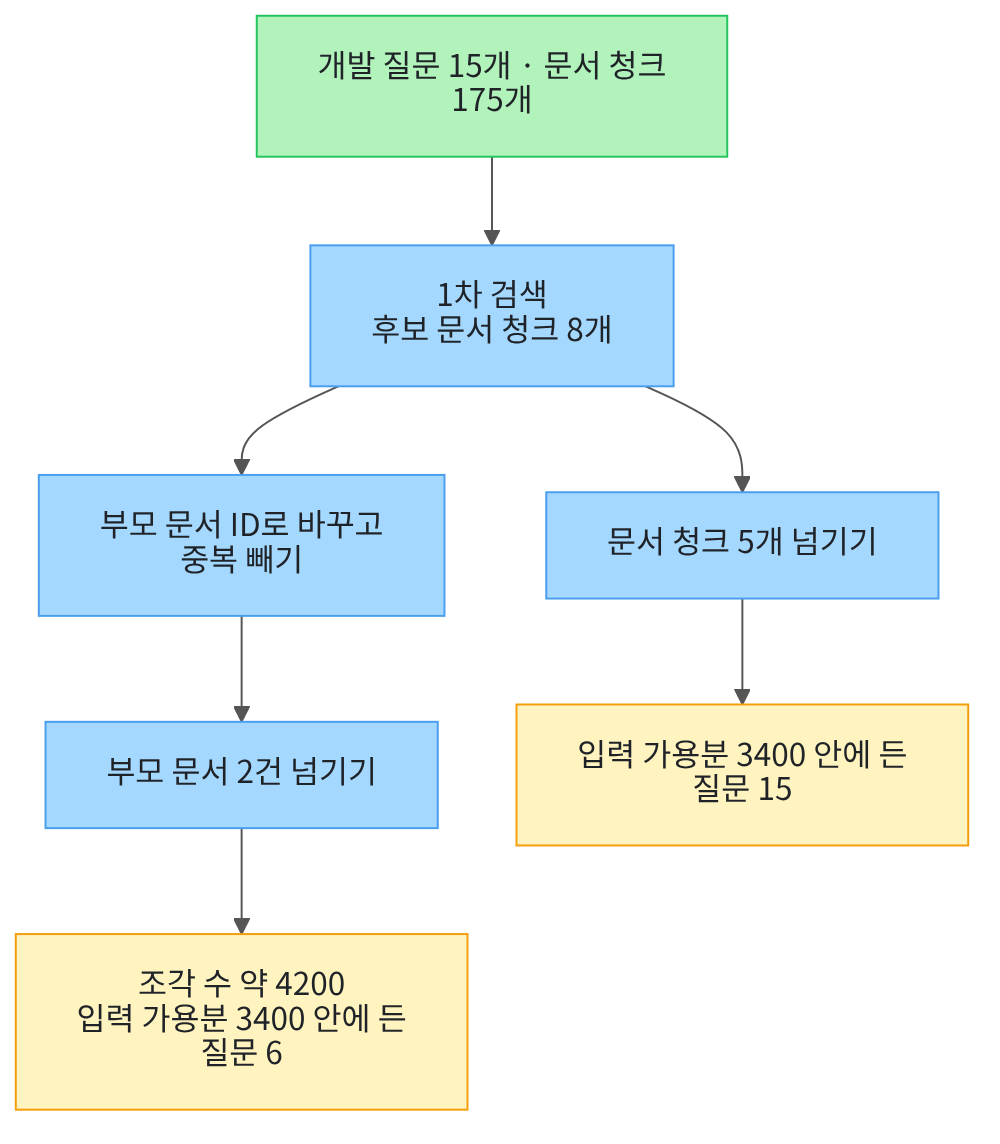

## 1. 준비

첫 셀은 패키지 여섯 개를 설치하고 설치된 버전을 출력합니다.
07·08절 여섯 개에서 리랭커 꾸러미를 빼고 조각 수를 세는 꾸러미를 넣었습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2" "tiktoken==0.14.0" "numpy==2.5.3"
from importlib.metadata import version

print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))
print("tiktoken:", version("tiktoken"))
print("numpy:", version("numpy"))

Note: you may need to restart the kernel to use updated packages.
langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2
tiktoken: 0.14.0
numpy: 2.5.3


**결과 읽기** — 설치가 끝나면 `langchain-openai: 1.6.1`과 `tiktoken: 0.14.0`이 보입니다.
마지막 줄 `numpy: 2.5.3`은 도구 파일이 벡터 계산에 쓰는 패키지입니다. 여섯 줄이 모두 보이면 다음 셀로 넘어갑니다.

다음 셀은 이 절에서 쓸 이름 다섯 개를 불러옵니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.

이 노트북은 04·06·07·08절 함수 여섯 개와 앞 챕터 함수 두 개를 가져옵니다.
04절 `kiwi_terms()`, 06절 `fuse_rank()`, 07절 `parent_ids_of()`입니다.
08절 `eligible_items()`·`chunk_precision_at()`, Ch 8 `count_tokens()`, Ch 11 `recall_at()`도 가져옵니다.
07절과 같은 문서 청크 판 순위 함수 세 개도 함께 가져옵니다.
인자 모양은 5절과 7절에서 설명합니다.

In [2]:
# 자료 읽기·조각 수 세기·형태소 분석·임베딩·낱말 점수에 쓸 이름을 불러옵니다
import json
import os

import tiktoken
from kiwipiepy import Kiwi
from langchain_openai import OpenAIEmbeddings
from rank_bm25 import BM25Okapi
# 04·06·07·08절과 Ch 8·Ch 11 함수, 문서 청크 판 순위 함수 열 개를 도구 파일에서 가져옵니다
from rag_tools import chunk_precision_at, count_tokens, eligible_items, fuse_rank
from rag_tools import kiwi_terms, parent_ids_of, rank_chunks_by_bm25, rank_chunks_by_distance
from rag_tools import recall_at, unique_chunk_ids

print("불러온 이름:", "json", "tiktoken", "Kiwi", "OpenAIEmbeddings", "BM25Okapi")

불러온 이름: json tiktoken Kiwi OpenAIEmbeddings BM25Okapi


**결과 읽기** — 출력 줄은 `불러온 이름:` 뒤에 이름 다섯 개가 붙은 한 줄입니다.
도구 파일에서 가져온 함수 열 개는 출력하지 않습니다.

다음 셀은 API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True` 하나입니다.
키 값은 출력하지 않습니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~08절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.

다음 셀은 07·08절과 같은 자료 두 벌을 읽습니다.
부모 문서 글은 이 절에서 통째로 넘길 글이라 ID로 찾을 수 있게 짝지어 둡니다.

In [5]:
# 07·08절과 같은 파일을 읽고 부모 문서 글도 ID로 찾을 수 있게 둡니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/advanced-documents.json", encoding="utf-8") as file:
    documents = json.loads(file.read())
with open(data_path + "/advanced-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
parents = documents["parents"]
chunks = documents["chunks"]
parent_text_by_id = {}
for parent in parents:
    # 문서 청크와 같은 모양으로 제목과 본문을 이어 붙입니다
    parent_text_by_id[parent["doc_id"]] = parent["title"] + " " + parent["text"]
print("부모 문서 수:", len(parents))
print("문서 청크 수:", len(chunks))
print("질문 수:", len(queries))

부모 문서 수: 6
문서 청크 수: 175
질문 수: 30


**결과 읽기** — `부모 문서 수: 6`과 `문서 청크 수: 175`, `질문 수: 30`이 보입니다.
07·08절과 같은 파일이라 세 값도 같습니다.
문서 청크 175개는 이 부모 문서 6건을 나눈 것입니다.

## 2. 개발 묶음 가리기

Ch 11이 정한 약속은 개발 15문항으로 설정을 고르는 것입니다.
시험 15문항은 설정을 다 고른 뒤 12절에서 한 번만 씁니다.
답할 수 없는 질문과 정답 ID가 빈 질문은 준비 셀에서 가져온 08절 함수 `eligible_items()`로 거릅니다.
다음 셀이 그 함수로 개발 묶음을 가립니다.

In [6]:
# 질문 30개에서 개발 묶음만 고르고 답할 수 있는 질문만 남깁니다
dev_all = []
for query in queries:
    if query["split"] == "dev":
        dev_all.append(query)
dev_queries = eligible_items(dev_all)
print("개발 질문 수:", len(dev_queries))
print("시험 질문 수:", len(queries) - len(dev_all))
print("첫 개발 질문:", dev_queries[0]["qid"], "|", dev_queries[0]["question"])
print("그 질문의 정답 부모 문서 ID:", dev_queries[0]["gold_doc_ids"])

개발 질문 수: 15
시험 질문 수: 15
첫 개발 질문: Q001 | 미르시립도서관의 정기 휴관일은 언제인가요?
그 질문의 정답 부모 문서 ID: ['E01']


**결과 읽기** — `개발 질문 수: 15`와 `시험 질문 수: 15`가 보입니다.
줄 `첫 개발 질문:` 뒤에 질문 ID와 질문 글이 있습니다.
정답 칸 값은 `['E01']`처럼 목록이고 값은 부모 문서 ID입니다.

## 3. 이 절에서 쓸 값 정하기

01~08절에서 쓴 값 세 개를 그대로 다시 정합니다.

In [7]:
# 01~08절에서 쓴 값을 그대로 다시 정합니다
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
rank_constant = 60
equal_weights = [1.0, 1.0]
print("남길 품사 표시:", keep_tags)
print("순위 상수:", rank_constant)
print("같은 가중치:", equal_weights)

남길 품사 표시: ['NNG', 'NNP', 'NNB', 'NR', 'VV', 'VA', 'MAG', 'SN', 'SL']
순위 상수: 60
같은 가중치: [1.0, 1.0]


**결과 읽기** — 줄 `순위 상수: 60`과 `같은 가중치: [1.0, 1.0]`은 06~08절과 같은 값입니다.
라벨 줄 `남길 품사 표시:` 뒤에는 이름 아홉 개가 있습니다.

다음 셀은 이 절에서 견줄 값을 정합니다.
넘길 부모 수는 부모 문서를 몇 건까지 넘길지 정한 수입니다.
08절 보고 자리가 문서 청크를 세는 자리라면 이 값은 부모 문서를 세는 자리입니다.

In [8]:
# 08절 후보 수와 두 자리를 잇고 이 절에서 견줄 넘길 부모 수를 더합니다
candidate_count = 8
candidate_counts = [2, 4, 8]
recall_place = 3
report_place = 5
parent_limit = 2
print("후보 수:", candidate_count)
print("견줄 후보 수 세 가지:", candidate_counts)
print("보고 자리:", report_place)
print("넘길 부모 수:", parent_limit)

후보 수: 8
견줄 후보 수 세 가지: [2, 4, 8]
보고 자리: 5
넘길 부모 수: 2


**결과 읽기** — `후보 수: 8`과 `보고 자리: 5`는 08절에서 쓴 값입니다.
줄 `넘길 부모 수: 2`가 이 절에서 새로 정한 값입니다.
라벨 줄 `견줄 후보 수 세 가지:` 뒤에 값 `[2, 4, 8]`이 있습니다.

## 4. 검색에 쓸 재료 만들기

문서 청크마다 제목과 본문을 이어 붙여 글 하나로 만듭니다.
청크 ID로 부모 문서 ID와 글을 찾을 수 있게 짝도 함께 만들어 둡니다.

In [9]:
# 문서 청크마다 제목과 본문을 이어 붙이고 청크 ID·부모 문서 ID·글을 짝지어 둡니다
chunk_texts = []
chunk_ids = []
parent_by_chunk = {}
text_by_chunk = {}
for chunk in chunks:
    chunk_text = chunk["title"] + " " + chunk["text"]
    chunk_texts.append(chunk_text)
    chunk_ids.append(chunk["chunk_id"])
    parent_by_chunk[chunk["chunk_id"]] = chunk["parent_id"]
    text_by_chunk[chunk["chunk_id"]] = chunk_text
all_chunk_count = len(chunk_ids)
print("이어 붙인 글 수:", len(chunk_texts))
print("첫 문서 청크 ID:", chunk_ids[0])

이어 붙인 글 수: 175
첫 문서 청크 ID: E01-P01-C01


**결과 읽기** — `이어 붙인 글 수: 175`가 보입니다.
줄 `첫 문서 청크 ID: E01-P01-C01`의 이름은 부모 ID와 쪽 번호, 문서 청크 번호를 이은 것입니다.
이름 앞머리 `E01`이 그 문서 청크의 부모 문서 ID입니다.

다음 셀은 벡터 거리 쪽 재료를 만듭니다. 01~08절과 같은 모델을 씁니다.

In [10]:
# 01~08절과 같은 모델로 문서 청크와 개발 질문을 벡터로 바꿉니다(임베딩 요청 16번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
chunk_vectors = embedding_model.embed_documents(chunk_texts)
query_vectors = []
for query in dev_queries:
    query_vectors.append(embedding_model.embed_query(query["question"]))
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 청크 벡터 수:", len(chunk_vectors))
print("질문 벡터 수:", len(query_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 청크 벡터 수: 175
질문 벡터 수: 15


**결과 읽기** — `벡터의 숫자 개수 설정: 256`과 `문서 청크 벡터 수: 175`가 보입니다.
출력 줄 `질문 벡터 수: 15`까지 나오면 임베딩 요청 열여섯 번이 끝났습니다.
이 노트북의 출력은 2026-09-21에 이 모델로 실행한 결과입니다.

## 5. 앞 절 함수의 인자 확인하기

후보를 만드는 함수는 준비 셀에서 도구 파일로부터 가져왔습니다.
두 순위는 07·08절과 같은 문서 청크 판 `rank_chunks_by_distance()`와 `rank_chunks_by_bm25()`가 만듭니다.
합치기는 06절 `fuse_rank()`가 맡고 순위 상수를 셋째 인자로 받습니다.

부모 문서를 다루는 함수 두 개는 짝 사전 `parent_by_chunk`를 인자로 받습니다.
07절 `parent_ids_of()`는 둘째 인자로, 08절 `chunk_precision_at()`은 넷째 인자로 받습니다.
07·08절 판은 이 짝 사전을 함수 안에서 바로 읽었습니다.

## 6. 후보 목록 만들기

다음 셀은 문서 청크의 검색 낱말 목록으로 BM25 모델을 만듭니다.
분석기를 만드는 줄 `kiwi = Kiwi()`는 1초 안팎 걸립니다.

In [11]:
# 04~08절과 같은 형태소 분석기로 문서 청크마다 검색 낱말 목록을 만들고 BM25 모델을 만듭니다
kiwi = Kiwi()
kiwi_corpus = []
for text in chunk_texts:
    kiwi_corpus.append(kiwi_terms(kiwi, text, keep_tags))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 청크 수:", bm25_model.corpus_size)
print("문서 청크 하나의 평균 검색 낱말 수:", round(bm25_model.avgdl, 2))

검색 낱말 목록 수: 175
BM25 모델이 본 문서 청크 수: 175
문서 청크 하나의 평균 검색 낱말 수: 44.01


**결과 읽기** — `검색 낱말 목록 수: 175`와 `BM25 모델이 본 문서 청크 수: 175`가 보입니다.
줄 `문서 청크 하나의 평균 검색 낱말 수: 44.01`은 07·08절과 같은 값입니다.

다음 셀은 개발 질문마다 두 순위를 합쳐 앞자리 여덟 개를 후보로 자릅니다.

In [12]:
# 개발 질문마다 두 순위를 합쳐 앞자리 여덟 개를 후보로 자릅니다(07·08절과 같은 방법)
candidate_sets = {}
for query_index in range(len(dev_queries)):
    question_id = dev_queries[query_index]["qid"]
    distance_hits = rank_chunks_by_distance(query_vectors[query_index], chunk_vectors, chunk_ids, all_chunk_count)
    question_terms = kiwi_terms(kiwi, dev_queries[query_index]["question"], keep_tags)
    score_hits = rank_chunks_by_bm25(bm25_model, question_terms, chunk_ids, all_chunk_count)
    ranking_list = [unique_chunk_ids(distance_hits), unique_chunk_ids(score_hits)]
    fused_ids = fuse_rank(ranking_list, equal_weights, rank_constant)
    candidate_sets[question_id] = fused_ids[:candidate_count]
print("만든 후보 목록 수:", len(candidate_sets))
print("후보 목록 하나의 문서 청크 수:", len(candidate_sets[dev_queries[0]["qid"]]))

만든 후보 목록 수: 15
후보 목록 하나의 문서 청크 수: 8


**결과 읽기** — `만든 후보 목록 수: 15`와 `후보 목록 하나의 문서 청크 수: 8`이 보입니다.
07·08절과 같은 1차 검색이라 후보 목록도 같은 방법으로 만든 것입니다.

## 7. 넘길 글의 길이를 재는 자 만들기

여기까지가 08절과 같습니다. 이제 찾은 다음에 무엇을 넘길지를 봅니다.
넘길 글이 길면 다음 단계 모델의 입력 자리를 많이 차지합니다.
그래서 먼저 길이를 재는 자를 만듭니다.
Ch 8 01절에서 쓴 토큰화 규칙과 예산 식을 그대로 씁니다.

In [13]:
# Ch 8 01절과 같은 토큰화 규칙을 불러오고 같은 식으로 입력 가용분을 냅니다
encoding = tiktoken.encoding_for_model("gpt-5.4-mini")
total_budget = 4000
output_reserve = 500
safety_margin = 100
# 예산에서 답을 쓸 자리와 여유 자리를 먼저 떼면 입력에 쓸 수 있는 조각 수가 남습니다
available = total_budget - output_reserve - safety_margin
print("토큰화 규칙 이름:", encoding.name)
print("수업 예산:", total_budget)
print("출력 예약분:", output_reserve)
print("여유분:", safety_margin)
print("입력 가용분:", available)

토큰화 규칙 이름: o200k_base
수업 예산: 4000
출력 예약분: 500
여유분: 100
입력 가용분: 3400


**결과 읽기** — `토큰화 규칙 이름: o200k_base`는 Ch 8 01절에서 본 이름과 같습니다.
줄 `입력 가용분: 3400`은 수업 예산 4000에서 500과 100을 뺀 값입니다.
답을 쓰는 모델은 이 절에서 부르지 않고 넘길 글의 길이만 잽니다.

글 하나의 조각 수는 준비 셀에서 가져온 Ch 8 01절 함수 `count_tokens()`로 셉니다.
도구 파일 판은 토큰화 규칙 `encoding`을 첫 인자로 받습니다.
조각은 Ch 5에서 배운 대로 모델이 글을 처리하는 단위입니다.
다음 셀은 글 목록의 조각 수를 모두 더하는 함수입니다.

In [14]:
# 글 목록의 글마다 조각 수를 세어 모두 더합니다
def total_tokens(text_list):
    total = 0
    for one_text in text_list:
        total = total + count_tokens(encoding, one_text)
    return total

정의 셀이라 출력이 없습니다.

다음 셀은 부모 문서 여섯 건의 길이를 봅니다.

In [15]:
# 부모 문서 여섯 건의 글자 수와 조각 수를 봅니다
print("부모 문서 ID | 글자 수 | 조각 수")
for parent in parents:
    parent_text = parent_text_by_id[parent["doc_id"]]
    print(parent["doc_id"], "|", len(parent_text), "|", count_tokens(encoding, parent_text))

부모 문서 ID | 글자 수 | 조각 수
E01 | 3034 | 1913
E02 | 2747 | 1799
H01 | 4964 | 3172
H02 | 4400 | 2940
M01 | 3917 | 2421
M02 | 4938 | 3283


**결과 읽기** — 라벨 줄 아래 여섯 줄이 나옵니다.
줄 `E01 | 3034 | 1913`은 글자 3034자가 조각 1913개라는 뜻입니다.
가장 긴 `M02`는 글자 `4938`자에 조각 `3283`개입니다.
가장 짧은 `E02`도 조각 `1799`개입니다.
부모 한 건만 넘겨도 입력 가용분 3400의 절반을 넘게 씁니다.

## 8. 부모 문서로 넓혀 넣기

후보는 문서 청크 목록이고 넘길 것은 부모 문서 글입니다.
07절 `parent_ids_of()`가 부모 문서 ID로 바꾸고 중복까지 빼 줍니다.
다음 셀은 그 목록을 넘길 부모 수까지 자르고 글로 바꿉니다.

In [16]:
# 후보 문서 청크의 부모 문서를 넘길 부모 수까지만 글 목록으로 만듭니다
def parent_texts_of(found_chunk_ids, parent_limit):
    # 중복 빼기는 07절 parent_ids_of()가 이미 하므로 앞에서 자르기만 합니다
    parent_ids = parent_ids_of(found_chunk_ids, parent_by_chunk)
    picked = []
    for parent_id in parent_ids[:parent_limit]:
        picked.append(parent_text_by_id[parent_id])
    return picked

정의 셀이라 출력이 없습니다.
새 함수는 이 하나이고 중복 빼기는 07절 함수가 그대로 합니다.

다음 셀은 넘길 글 목록 열다섯 벌을 한 번에 재는 함수입니다.
셋째 값은 조각 수가 입력 가용분 안에 든 질문 수입니다.

In [17]:
# 넘길 글 목록 열다섯 벌을 받아 글 수·조각 수의 질문 평균과 입력 가용분에 든 질문 수를 냅니다
def summarize(text_lists):
    count_total = 0
    token_total = 0
    fit_count = 0
    for text_list in text_lists:
        tokens = total_tokens(text_list)
        count_total = count_total + len(text_list)
        token_total = token_total + tokens
        # 입력 가용분보다 길면 다음 단계에 그대로 넣을 수 없습니다
        if tokens <= available:
            fit_count = fit_count + 1
    return round(count_total / len(text_lists), 1), round(token_total / len(text_lists)), fit_count

정의 셀이라 출력이 없습니다.

## 9. 실행 1 — 한 질문에서 부모까지

07절에서 본 질문 하나를 그대로 씁니다.
실행 전에 예상해 봅니다. 후보 여덟 개의 부모는 여덟 건보다 적을 것입니다.

In [18]:
# 07절과 같은 질문에서 후보 여덟 개의 부모 차례와 부모 글의 길이를 봅니다
example_index = 1
example_id = dev_queries[example_index]["qid"]
example_found = candidate_sets[example_id]
example_parents = parent_ids_of(example_found, parent_by_chunk)
print("고른 질문:", example_id, "|", dev_queries[example_index]["question"])
print("후보의 부모 문서 차례:", example_parents)
print("부모 문서 ID | 글자 수 | 조각 수")
for parent_id in example_parents:
    parent_text = parent_text_by_id[parent_id]
    print(parent_id, "|", len(parent_text), "|", count_tokens(encoding, parent_text))

고른 질문: Q002 | 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
후보의 부모 문서 차례: ['E01', 'E02']
부모 문서 ID | 글자 수 | 조각 수
E01 | 3034 | 1913
E02 | 2747 | 1799


**결과 읽기** — 줄 `고른 질문: Q002`는 07절 실행 1과 같은 질문입니다.
줄 `후보의 부모 문서 차례: ['E01', 'E02']`에서 문서 청크 여덟 개가 부모 두 건으로 줄었습니다.
라벨 줄 아래 두 줄이 그 부모의 길이입니다.
부모 문서 `E01`은 조각 `1913`개이고 `E02`는 조각 `1799`개입니다.

다음 셀은 같은 질문에서 후보 수만 바꾸고 넘길 두 건의 길이도 잽니다.

In [19]:
# 같은 질문에서 후보 수만 바꿔 부모 차례를 보고 넘길 두 건의 길이도 잽니다
print("후보 수 | 부모 문서 차례")
for candidate_k in candidate_counts:
    print(candidate_k, "|", parent_ids_of(example_found[:candidate_k], parent_by_chunk))
example_texts = parent_texts_of(example_found, parent_limit)
example_tokens = total_tokens(example_texts)
print("넘길 부모 두 건의 조각 수 합:", example_tokens)
print("입력 가용분에 드는가:", example_tokens <= available)

후보 수 | 부모 문서 차례
2 | ['E01']
4 | ['E01']
8 | ['E01', 'E02']


넘길 부모 두 건의 조각 수 합: 3712
입력 가용분에 드는가: False


**결과 읽기** — 라벨 줄 아래 세 줄이 나옵니다.
후보 `2`와 후보 `4`에서는 부모가 `['E01']` 한 건뿐입니다.
후보 `8`에서 `['E01', 'E02']` 두 건이 됩니다.
후보를 네 배로 늘려도 부모는 한 건만 늘었습니다.
여러 문서 청크가 같은 부모에서 나왔기 때문입니다.

줄 `넘길 부모 두 건의 조각 수 합: 3712`는 두 부모 글을 더한 길이입니다.
줄 `입력 가용분에 드는가: False`는 그 길이가 3400을 넘었다는 뜻입니다.
이 질문에서는 부모 두 건을 통째로 넘길 수 없습니다.

## 10. 실행 1 — 열다섯 질문 평균

다음 셀은 질문마다 넘길 글 목록을 두 벌 만듭니다.
한 벌은 08절까지 쓰던 문서 청크 다섯 개이고 다른 한 벌은 부모 문서 두 건입니다.

In [20]:
# 질문마다 넘길 글 목록을 두 벌 만듭니다(문서 청크 다섯 개 / 부모 문서 두 건)
chunk_lists = []
parent_lists = []
for item in dev_queries:
    found_ids = candidate_sets[item["qid"]][:candidate_count]
    picked = []
    for chunk_id in found_ids[:report_place]:
        picked.append(text_by_chunk[chunk_id])
    chunk_lists.append(picked)
    parent_lists.append(parent_texts_of(found_ids, parent_limit))
print("만든 글 목록 벌 수:", len(chunk_lists), "|", len(parent_lists))

만든 글 목록 벌 수: 15 | 15


**결과 읽기** — 출력 줄은 `만든 글 목록 벌 수: 15 | 15` 하나입니다.
질문 하나에 목록 한 벌씩입니다.

다음 셀이 두 벌의 길이를 견줍니다.
실행 전에 예상해 봅니다. 부모 문서 쪽이 훨씬 길 것입니다.

In [21]:
# 두 벌을 같은 함수로 재어 넘길 글의 길이를 견줍니다
chunk_row = summarize(chunk_lists)
parent_row = summarize(parent_lists)
print("넘기는 단위 | 글 수 평균 | 조각 수 평균 | 입력 가용분에 든 질문 수")
print("문서 청크 |", chunk_row[0], "|", chunk_row[1], "|", chunk_row[2])
print("부모 문서 |", parent_row[0], "|", parent_row[1], "|", parent_row[2])

넘기는 단위 | 글 수 평균 | 조각 수 평균 | 입력 가용분에 든 질문 수
문서 청크 | 5.0 | 600 | 15
부모 문서 | 1.6 | 4206 | 6


**결과 읽기** — 라벨 줄 아래 두 줄이 나옵니다.
줄 `문서 청크 | 5.0 | 600 | 15`는 다섯 개를 넘길 때 조각 600개라는 뜻입니다.
그 열다섯 질문이 모두 입력 가용분 안에 들었습니다.

줄 `부모 문서 | 1.6 | 4206 | 6`은 글 수가 더 적은데 조각 수는 일곱 배라는 뜻입니다.
부모 문서를 통째로 넘기면 입력 가용분에 드는 질문이 여섯으로 줄었습니다.
글 수 평균 `1.6`은 후보 여덟 개의 부모가 한 건뿐인 질문이 섞여 있어서 2보다 작습니다.
두 줄의 조각 수 평균은 다시 실행하면 몇 개쯤 달라질 수 있습니다.

다음 셀은 08절 두 지표를 같은 후보에서 다시 냅니다.

In [22]:
# 08절 두 지표를 같은 후보에서 다시 내고 넘긴 부모 목록의 재현율도 함께 냅니다
recall_total = 0.0
precision_total = 0.0
passed_total = 0.0
for item in dev_queries:
    found_ids = candidate_sets[item["qid"]][:candidate_count]
    parent_ids = parent_ids_of(found_ids, parent_by_chunk)
    recall_total = recall_total + recall_at(parent_ids, item["gold_doc_ids"], recall_place)
    precision_total = precision_total + chunk_precision_at(found_ids, item["gold_doc_ids"], report_place, parent_by_chunk)
    passed_total = passed_total + recall_at(parent_ids, item["gold_doc_ids"], parent_limit)
print("부모 문서 재현율 자리 3:", round(recall_total / len(dev_queries), 3))
print("문서 청크 정밀도 자리 5:", round(precision_total / len(dev_queries), 3))
print("넘긴 부모 목록의 재현율:", round(passed_total / len(dev_queries), 3))

부모 문서 재현율 자리 3: 1.0
문서 청크 정밀도 자리 5: 0.84
넘긴 부모 목록의 재현율: 1.0


**결과 읽기** — `부모 문서 재현율 자리 3: 1.0`은 08절 1차 후보 줄과 같은 자리입니다.
줄 `넘긴 부모 목록의 재현율: 1.0`은 넘긴 부모 두 건 안에 정답 부모가 모두 들어왔다는 뜻입니다.
두 재현율은 가장 큰 값에 붙어 있어 설정을 가르지 못합니다.
줄 `문서 청크 정밀도 자리 5: 0.84`는 08절과 같은 방법으로 낸 값입니다.

## 11. 값 바꿔 보기 — 넘길 부모 수를 1로

바꿀 값은 넘길 부모 수 하나입니다.
후보 수와 보고 자리, 후보 목록은 그대로 둡니다.
실행 전에 예상해 봅니다. 조각 수는 줄고 재현율은 그대로일 것입니다.

In [23]:
# 값 바꿔 보기: 넘길 부모 수만 1로 줄여 같은 값을 다시 냅니다
parent_limit = 1
small_lists = []
passed_total = 0.0
for item in dev_queries:
    found_ids = candidate_sets[item["qid"]][:candidate_count]
    small_lists.append(parent_texts_of(found_ids, parent_limit))
    parent_ids = parent_ids_of(found_ids, parent_by_chunk)
    passed_total = passed_total + recall_at(parent_ids, item["gold_doc_ids"], parent_limit)
small_row = summarize(small_lists)
print("넘길 부모 수:", parent_limit)
print("넘기는 단위 | 글 수 평균 | 조각 수 평균 | 입력 가용분에 든 질문 수")
print("부모 문서 |", small_row[0], "|", small_row[1], "|", small_row[2])
print("넘긴 부모 목록의 재현율:", round(passed_total / len(dev_queries), 3))

넘길 부모 수: 1
넘기는 단위 | 글 수 평균 | 조각 수 평균 | 입력 가용분에 든 질문 수
부모 문서 | 1.0 | 2502 | 15
넘긴 부모 목록의 재현율: 1.0


**결과 읽기** — 줄 `부모 문서 | 1.0 | 2502 | 15`가 나옵니다.
조각 수 평균이 4206에서 2502로 줄고 입력 가용분에 든 질문이 여섯에서 열다섯이 되었습니다.
줄 `넘긴 부모 목록의 재현율: 1.0`은 부모를 하나만 넘겨도 그대로입니다.
1차 후보의 1위 문서 청크가 늘 정답 부모에서 나왔기 때문입니다.
부모 문서가 6건뿐인 이 자료에서는 재현율로 두 설정을 가를 수 없습니다.

## 정리

1. 후보 여덟 개의 부모 문서는 중복을 빼면 질문 평균 두 건 아래였습니다.
2. 부모 문서를 통째로 넘기면 문서 청크 다섯 개를 넘길 때보다 조각 수가 일곱 배 가까이 늘어 4200을 넘었습니다.
3. 넘길 부모 수를 1로 줄이면 조각 수가 2502가 되고 열다섯 질문이 모두 입력 가용분에 들었습니다.

10절에서는 넘길 목록에서 서로 닮은 문서 청크를 줄이는 MMR을 봅니다.